# Text-to-Image (TTI) — local image generation on Apple Silicon

Pick a **model family** and a **size**, then run the pipeline end to end:

1. Select the model from the `MODEL_NAME` registry (`APPLE → TTI → FAMILY → SIZE`)
2. Review the models: parameters, steps, resolution and memory
3. Load the model
4. Load the prompts (`prompts/tti_prompts_10.csv`)
5. Generate one image per prompt, measuring speed, memory and energy, with per-prompt macmon capture
6. View and save the images
7. Check what the images show (a vision model captions each one) and the cost of the run
8. Compare the sizes of the selected family
9. Combine every model run so far

All models run on **MLX** on the Apple GPU:

- **Stable Diffusion XL** with Apple's MLX Stable Diffusion code from
  [`mlx-examples`](https://github.com/ml-explore/mlx-examples/tree/main/stable_diffusion), copied into `tti_backends/mlx_stable_diffusion/`
  (MIT license) with two small changes for SDXL base (see its README)
- **FLUX.2-klein** with [`mflux`](https://github.com/filipstrand/mflux), an MLX implementation of recent image models

**MLX compatibility of the original registry.** `stable-diffusion-xl-base-1.0` runs on MLX (above).
`stable-diffusion-3.5-large-turbo` cannot be used: its weights are gated on Hugging Face (they need an approved access
token), and the only MLX implementation of Stable Diffusion 3.5 (Argmax's DiffusionKit) requires MLX 0.17, which would
break every other notebook in this project. mflux does not implement Stable Diffusion 3.5.

## 1. Configuration — model registry

In [1]:
import os
import sys
from pathlib import Path

# Run from the project root, whether this notebook is opened from notebooks/ or from the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'prompts').is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
# The saved Hugging Face token is invalid; every model here is public, so don't send it
os.environ.setdefault('HF_HUB_DISABLE_IMPLICIT_TOKEN', '1')

# APPLE -> TTI -> family -> size -> model
MODEL_NAME = {
    'APPLE': {
        'TTI': {
            'Stable-Diffusion-XL': {                       # original registry (MEDIUM)
                'MEDIUM': 'stable-diffusion-xl-base-1.0',  # 3.5B (UNet 2.6B + 2 text encoders)
            },
            'FLUX.2-klein': {                              # Black Forest Labs; the 9B size is gated
                'SMALL': 'FLUX.2-klein-4B',                #  4B transformer + Qwen3 text encoder
            },
        },
    },
}

# Model -> how it runs. Each entry: Hugging Face repo, MLX library, default steps, guidance, precision
MODELS = {
    'stable-diffusion-xl-base-1.0': dict(repo='stabilityai/stable-diffusion-xl-base-1.0', library='mlx-examples',
                                         steps=30, guidance=7.0, precision='float16 (VAE float32)'),
    'FLUX.2-klein-4B':              dict(repo='black-forest-labs/FLUX.2-klein-4B', library='mflux',
                                         steps=4, guidance=1.0, precision='8-bit'),
}

PLATFORM, TASK = 'APPLE', 'TTI'
# Environment variables TTI_FAMILY / TTI_SIZE / TTI_PROMPTS / TTI_COMPARE override these, for running from the terminal
FAMILY = os.environ.get('TTI_FAMILY', 'Stable-Diffusion-XL')   # 'Stable-Diffusion-XL' | 'FLUX.2-klein'
SIZE = os.environ.get('TTI_SIZE', 'MEDIUM')                    # only the sizes listed above
RUN_FAMILY_COMPARISON = os.environ.get('TTI_COMPARE', '1') == '1'

model_name = MODEL_NAME[PLATFORM][TASK][FAMILY][SIZE]
cfg = MODELS[model_name]

PROMPT_SET = os.environ.get('TTI_PROMPTS', 'tti_prompts_10')   # a CSV in prompts/ with columns id,prompt
INPUT_PATH = Path('prompts') / f'{PROMPT_SET}.csv'
OUTPUT_DIR = Path('outputs/tti') / FAMILY   # outputs/tti/<family>/<params>/<prompt set>/ (see out_dir, section 2)
WIDTH = HEIGHT = 1024                       # native resolution of all three models
SEED = 0                                    # same seed for every prompt and model, so runs are repeatable
CAPTION_MODEL = 'mlx-community/Qwen2-VL-2B-Instruct-4bit'   # describes each generated image (section 7)
POWER_SAMPLE_MS = 100
ELECTRICITY_USD_PER_KWH = 0.15

print(f"{PLATFORM} / {TASK} / {FAMILY} / {SIZE} -> {model_name} -> {cfg['repo']}  ({cfg['library']}, {cfg['steps']} steps)")
print(f'Prompts: {INPUT_PATH}  |  {WIDTH} x {HEIGHT}')

APPLE / TTI / FLUX.2-klein / SMALL -> FLUX.2-klein-4B -> black-forest-labs/FLUX.2-klein-4B  (mflux, 4 steps)
Prompts: prompts/tti_prompts_10.csv  |  1024 x 1024


## 2. Models — sizes, steps and memory

- **Stable Diffusion XL base 1.0** (Stability AI, 2023): a 2.6B-parameter UNet with two CLIP text encoders. It needs
  about 30 denoising steps with classifier-free guidance (each step runs the UNet twice, with and without the prompt).
  Its VAE is run in float32, because in float16 it is known to overflow.
- **FLUX.2-klein-4B** (Black Forest Labs): a step-distilled transformer that needs only 4 steps.
FLUX.2-klein is quantized to **8-bit** when loaded (its text encoder alone is several GB in 16-bit).

**What an image costs for a local model.** There is **no per-image API fee ($0)**. What an image costs is **time**,
**memory** and **energy** (section 7).

In [2]:
import mlx.core as mx
import pandas as pd

GB = 1e9
DEVICE = mx.device_info()
# MLX keeps freed GPU buffers in a cache for reuse. At 1024 x 1024 the per-image buffers are large, and an unbounded
# cache grows until macOS swaps, so cap it (it only affects memory reuse, not the images)
mx.set_cache_limit(4 * 1024**3)

SPECS = pd.DataFrame([
    # model,                         params (B), architecture,                              download_gb
    ('stable-diffusion-xl-base-1.0', 3.47,       'UNet + 2 CLIP text encoders + VAE',      7.11),
    ('FLUX.2-klein-4B',              4.0,        'rectified-flow transformer + Qwen3 text encoder', 23.72),
], columns=['model', 'params_b', 'architecture', 'download_gb']).set_index('model')

# Output subfolder per model, named by its parameter count: outputs/tti/<family>/<params>/<prompt set>/
PARAM_FOLDER = {'stable-diffusion-xl-base-1.0': '3.5B', 'FLUX.2-klein-4B': '4B'}

def family_of(name):
    return next(f for f, sizes in MODEL_NAME[PLATFORM][TASK].items() if name in sizes.values())

def size_of(name):
    return next(sz for sizes in MODEL_NAME[PLATFORM][TASK].values() for sz, n in sizes.items() if n == name)

def out_dir(name):
    d = OUTPUT_DIR / PARAM_FOLDER[name] / PROMPT_SET
    d.mkdir(parents=True, exist_ok=True)
    return d

rows = []
for family, sizes in MODEL_NAME[PLATFORM][TASK].items():
    for size, name in sizes.items():
        s, c = SPECS.loc[name], MODELS[name]
        rows.append({'': '▶' if name == model_name else '', 'Family': family, 'Size': size, 'Model': name,
                     'Params (B)': s.params_b, 'Architecture': s.architecture, 'Steps': c['steps'],
                     'Guidance': c['guidance'] if c['guidance'] is not None else '—', 'Precision': c['precision'],
                     'Library': c['library'], 'Download (GB)': f'{s.download_gb:.2f}', 'API cost': '$0 (local)'})
print(f"{DEVICE['device_name']}: {DEVICE['memory_size'] / GB:.0f} GB unified memory.  ▶ = selected model")
pd.DataFrame(rows).style.hide(axis='index')

Apple M5 Max: 52 GB unified memory.  ▶ = selected model


,Family,Size,Model,Params (B),Architecture,Steps,Guidance,Precision,Library,Download (GB),API cost
,Stable-Diffusion-XL,MEDIUM,stable-diffusion-xl-base-1.0,3.470000,UNet + 2 CLIP text encoders + VAE,30,7.000000,float16 (VAE float32),mlx-examples,7.11,$0 (local)
▶,FLUX.2-klein,SMALL,FLUX.2-klein-4B,4.000000,rectified-flow transformer + Qwen3 text encoder,4,1.000000,8-bit,mflux,23.72,$0 (local)


## 3. Load the model

In [3]:
import json
import time
import numpy as np
from PIL import Image
from tti_backends.mlx_stable_diffusion import StableDiffusionXL
from tti_backends.mlx_stable_diffusion.model_io import _MODELS as SD_MODELS, load_autoencoder

def load_tti_model(name):
    c = MODELS[name]
    t0 = time.perf_counter()
    if c['library'] == 'mlx-examples':
        model = StableDiffusionXL(c['repo'], float16=True)
        model.autoencoder = load_autoencoder(c['repo'], float16=False)   # SDXL's VAE overflows in float16
        model.ensure_models_are_loaded()
    else:
        from mflux.models.common.config import ModelConfig
        from mflux.models.flux2.variants.txt2img.flux2_klein import Flux2Klein
        model = Flux2Klein(quantize=8, model_config=ModelConfig.flux2_klein_4b())
    if c['library'] == 'mflux':
        mx.eval(model.parameters())   # mflux loads weights lazily; load them now so load time and memory are real
    return model, time.perf_counter() - t0

model, load_seconds = load_tti_model(model_name)
print(f"Loaded {cfg['repo']} in {load_seconds:.1f}s on {mx.default_device()}  |  weights in memory: {mx.get_active_memory() / GB:.2f} GB")

/Users/genailab/mlx-projects/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded black-forest-labs/FLUX.2-klein-4B in 1.8s on Device(gpu, 0)  |  weights in memory: 8.56 GB


## 4. Load the prompts

In [4]:
PROMPTS = pd.read_csv(INPUT_PATH, dtype={'id': str})
PROMPTS['id'] = PROMPTS['id'].str.zfill(2)
PROMPTS['words'] = PROMPTS.prompt.str.split().str.len()
PROMPTS['characters'] = PROMPTS.prompt.str.len()
print(f'Prompts: {INPUT_PATH} ({len(PROMPTS)} prompts)')
PROMPTS[['id', 'words', 'characters', 'prompt']].style.hide(axis='index')

Prompts: prompts/tti_prompts_10.csv (10 prompts)


id,words,characters,prompt
01,17,87,"3D render of a cute tropical fish in an aquarium on a dark blue background, digital art"
02,8,38,An armchair in the shape of an avocado
03,10,56,A van Gogh style painting of an American football player
04,15,79,A pencil and watercolor drawing of a bright city in the future with flying cars
05,6,45,An abstract visual of artificial intelligence
06,5,22,A Fat Cat playing Golf
07,11,60,A hand-drawn sailboat circled by birds on the sea at sunrise
08,15,79,A 3D render of a rainbow colored hot air balloon flying above a reflective lake
09,9,38,A Formula 1 car driving on a neon road
10,9,65,illustration of a dinosaur enjoying a peaceful fishing experience


## 5. Generate the images

One 1024 × 1024 image per prompt, with the same seed for every prompt and model.

**Power monitoring.** `macmon` (no sudo needed) runs in the background for the whole notebook, sampling the chip's
power sensors about every 110 ms; each image's energy is the power integrated over the time it took to generate.
Readings are Apple's on-chip estimates, not a wall-meter measurement.

In [5]:
import atexit
import json
import shutil
import subprocess
import threading

class PowerMonitor:
    """Runs `macmon pipe` in the background and keeps every sample.

    Each sample is the average over the interval since the previous one, so the energy in any time
    window is the sum of power x (overlap of that interval with the window).
    """
    def __init__(self, interval_ms):
        self.samples = []  # (time.perf_counter(), macmon sample dict)
        self.available = shutil.which('macmon') is not None
        if not self.available:
            print('macmon not found: power and energy metrics will be empty (install: brew install macmon)')
            return
        self.proc = subprocess.Popen(['macmon', 'pipe', '-i', str(interval_ms)],
                                     stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True)
        atexit.register(self.proc.terminate)
        threading.Thread(target=self._read, daemon=True).start()
        t_start = time.perf_counter()
        while len(self.samples) < 2 and time.perf_counter() - t_start < 5:  # macmon takes ~0.7 s to start
            time.sleep(0.05)
        self.available = len(self.samples) >= 2

    def _read(self):
        for line in self.proc.stdout:
            try:
                self.samples.append((time.perf_counter(), json.loads(line)))
            except json.JSONDecodeError:
                pass

    def wait_past(self, t, timeout=2.0):
        """Block until a sample covering time t has arrived."""
        deadline = time.perf_counter() + timeout
        while self.samples[-1][0] < t and time.perf_counter() < deadline:
            time.sleep(0.02)

    def window(self, a, b):
        """Samples overlapping [a, b], as (seconds of overlap, sample)."""
        return [(min(t, b) - max(t_prev, a), s)
                for (t_prev, _), (t, s) in zip(self.samples, self.samples[1:])
                if min(t, b) - max(t_prev, a) > 0]

def soc_power(s):
    return s['all_power'] + s['ram_power']  # CPU + GPU + Neural Engine + memory, in watts

def integrate(win, fn):
    return sum(overlap * fn(s) for overlap, s in win)

POWER_KEYS = ['gpu_util_avg_pct', 'gpu_power_avg_w', 'gpu_power_peak_w', 'soc_power_avg_w', 'gpu_temp_max_c',
              'energy_j', 'energy_net_j', 'power_samples']

def summarize_power(t0, t_end):
    if not POWER.available:
        return dict.fromkeys(POWER_KEYS)
    POWER.wait_past(t_end)
    run = POWER.window(t0, t_end)
    samples = [s for _, s in run]
    dur = t_end - t0
    e_soc = integrate(run, soc_power)
    return {
        'gpu_util_avg_pct': round(100 * integrate(run, lambda s: s['gpu_active_ratio']) / dur, 1),
        'gpu_power_avg_w': round(integrate(run, lambda s: s['gpu_power']) / dur, 1),
        'gpu_power_peak_w': round(max(s['gpu_power'] for s in samples), 1),
        'soc_power_avg_w': round(e_soc / dur, 1),
        'gpu_temp_max_c': round(max(s['temp']['gpu_temp_avg'] for s in samples), 1),
        'energy_j': round(e_soc, 2),
        'energy_net_j': round(e_soc - IDLE_SOC_W * dur, 2),
        'power_samples': len(run),
    }

POWER = PowerMonitor(POWER_SAMPLE_MS)
if POWER.available:
    time.sleep(1.0)  # idle baseline, measured with the model loaded but not running
    a, b = POWER.samples[0][0], POWER.samples[-1][0]
    IDLE_SOC_W = integrate(POWER.window(a, b), soc_power) / (b - a)
    print(f'Power monitor running (macmon, ~{POWER_SAMPLE_MS} ms samples). Idle chip power: {IDLE_SOC_W:.2f} W')

def cpu_clusters():
    """CPU cluster names and core counts from macOS (e.g. M5 Max: 6 'Super' + 12 'Performance' cores)."""
    def sysctl(key):
        return subprocess.run(['sysctl', '-n', key], capture_output=True, text=True).stdout.strip()
    return [(sysctl(f'hw.perflevel{i}.name') or f'level{i}', int(sysctl(f'hw.perflevel{i}.logicalcpu') or 0)) for i in (0, 1)]

CPU_CLUSTERS = cpu_clusters()
HARDWARE = {}   # model name -> hardware_metrics() for its whole run

def hardware_metrics(t0, t1):
    """GPU, CPU, Neural Engine (NPU), memory and whole-chip activity over [t0, t1], from the macmon samples.

    macmon calls the two CPU clusters 'pcpu' (perflevel0) and 'ecpu' (perflevel1); they are reported here
    under the names macOS gives them.
    """
    if not POWER.available:
        return None
    POWER.wait_past(t1)
    win = POWER.window(t0, t1)
    samples = [s for _, s in win]
    dur = t1 - t0
    avg = lambda fn: integrate(win, fn) / dur
    peak = lambda fn: max(fn(s) for s in samples)
    energy = lambda fn: round(integrate(win, fn), 2)
    pct = lambda x: round(100 * x, 1)
    (c0_name, c0_cores), (c1_name, c1_cores) = CPU_CLUSTERS
    c0, c1 = c0_name.lower(), c1_name.lower()
    ane = lambda s: s['ane_power']
    return {
        'gpu': {
            'avg_utilization_pct': pct(avg(lambda s: s['gpu_active_ratio'])),
            'peak_utilization_pct': pct(peak(lambda s: s['gpu_active_ratio'])),
            'avg_frequency_mhz': round(avg(lambda s: s['gpu_freq_mhz'])),
            'max_frequency_mhz': round(peak(lambda s: s['gpu_freq_mhz'])),
            'avg_power_watts': round(avg(lambda s: s['gpu_power']), 1),
            'peak_power_watts': round(peak(lambda s: s['gpu_power']), 1),
            'energy_joules': energy(lambda s: s['gpu_power']),
            'avg_temperature_c': round(avg(lambda s: s['temp']['gpu_temp_avg']), 1),
            'max_temperature_c': round(peak(lambda s: s['temp']['gpu_temp_avg']), 1),
        },
        'cpu': {
            'avg_utilization_pct': pct(avg(lambda s: s['cpu_active_ratio'])),
            'peak_utilization_pct': pct(peak(lambda s: s['cpu_active_ratio'])),
            f'{c0}_cores': c0_cores,
            f'{c0}_cores_avg_utilization_pct': pct(avg(lambda s: s['pcpu_active_ratio'])),
            f'{c0}_cores_avg_frequency_mhz': round(avg(lambda s: s['pcpu_freq_mhz'])),
            f'{c1}_cores': c1_cores,
            f'{c1}_cores_avg_utilization_pct': pct(avg(lambda s: s['ecpu_active_ratio'])),
            f'{c1}_cores_avg_frequency_mhz': round(avg(lambda s: s['ecpu_freq_mhz'])),
            'avg_power_watts': round(avg(lambda s: s['cpu_power']), 1),
            'peak_power_watts': round(peak(lambda s: s['cpu_power']), 1),
            'energy_joules': energy(lambda s: s['cpu_power']),
            'avg_temperature_c': round(avg(lambda s: s['temp']['cpu_temp_avg']), 1),
            'max_temperature_c': round(peak(lambda s: s['temp']['cpu_temp_avg']), 1),
        },
        'npu': {
            'name': 'Apple Neural Engine (ANE)',
            'used': peak(ane) > 0.05,
            'avg_power_watts': round(avg(ane), 2),
            'peak_power_watts': round(peak(ane), 2),
            'energy_joules': energy(ane),
            'note': 'MLX runs models on the GPU, so the Neural Engine stays idle (about 0 W) during these runs.',
        },
        'system_memory': {
            'avg_power_watts': round(avg(lambda s: s['ram_power']), 1),
            'energy_joules': energy(lambda s: s['ram_power']),
            'ram_total_gb': round(samples[0]['memory']['ram_total'] / 1e9, 1),
            'avg_ram_used_gb': round(avg(lambda s: s['memory']['ram_usage']) / 1e9, 1),
            'peak_ram_used_gb': round(peak(lambda s: s['memory']['ram_usage']) / 1e9, 1),
            'peak_swap_used_gb': round(peak(lambda s: s['memory']['swap_usage']) / 1e9, 2),
            'note': 'RAM used is for the whole Mac, including other apps, not just this model.',
        },
        'whole_chip': {
            'avg_power_watts': round(avg(soc_power), 1),
            'peak_power_watts': round(peak(soc_power), 1),
            'energy_joules': energy(soc_power),
            'idle_power_watts': round(IDLE_SOC_W, 2),
            'note': 'CPU + GPU + Neural Engine + memory.',
        },
        'measured_seconds': round(dur, 2),
        'power_samples': len(win),
    }

Power monitor running (macmon, ~100 ms samples). Idle chip power: 0.66 W


### Per-prompt metrics analysis

Every image is wrapped in `metrics_monitor_start()` / `metrics_monitor_stop()` from `macmon_metrics/metrics_monitor.py`,
which records a macmon time series for that image. Results go to a separate folder,
`metrics_analysis/tti/<family>/<params>/<prompt set>/`:

- `System_Level_Metrics/<prompt id>_system_metrics.csv`: CPU / GPU / NPU utilisation, power and temperature, RAM used
  and total system power, sampled every 100 ms while that image was generated
- `Model_Level_Metrics/<model>_prompt_metrics.csv`: one row per prompt (columns explained in section 7)

Section 9 combines every model's `Model_Level_Metrics` CSV into `metrics_analysis/tti/all_models_prompt_metrics_<prompt set>.csv`.

In [6]:
import macmon_metrics.metrics_monitor as mm
from macmon_metrics.metrics_monitor import metrics_monitor_start, metrics_monitor_stop, setup_output_directory

METRICS_ROOT = Path('metrics_analysis/tti')

def analysis_dirs(name):
    """(System_Level_Metrics, Model_Level_Metrics) folders for one model."""
    return setup_output_directory(str(METRICS_ROOT / family_of(name) / PARAM_FOLDER[name] / PROMPT_SET))

if mm._tracker is None:   # macmon takes about a second to start; start it before the first image
    mm._tracker = mm.MacMonTracker(binary_path=mm._resolve_macmon_binary())
    mm._tracker.start()
    time.sleep(1.5)

def generate_image(model, name, prompt):
    """Generate one image. Returns a PIL image and timings."""
    c = MODELS[name]
    mx.reset_peak_memory()
    t0 = time.perf_counter()
    if c['library'] == 'mlx-examples':
        t_first_step = None
        latents = model.generate_latents(prompt, n_images=1, num_steps=c['steps'], cfg_weight=c['guidance'],
                                         latent_size=(HEIGHT // 8, WIDTH // 8), seed=SEED)
        for x_t in latents:
            mx.eval(x_t)
            if t_first_step is None:
                t_first_step = time.perf_counter()
        t_denoised = time.perf_counter()
        x = model.decode(x_t.astype(mx.float32))
        mx.eval(x)
        image = Image.fromarray((np.array(x[0]) * 255).astype(np.uint8))
    else:
        result = model.generate_image(seed=SEED, prompt=prompt, num_inference_steps=c['steps'],
                                      height=HEIGHT, width=WIDTH, guidance=c['guidance'])
        image, t_first_step, t_denoised = result.image, None, None
    t_end = time.perf_counter()
    mx.clear_cache()   # release this image's buffers before the next one
    return {
        'image': image,
        'time_s': t_end - t0,
        'first_step_s': (t_first_step - t0) if t_first_step else None,
        'decode_s': (t_end - t_denoised) if t_denoised else None,
        'peak_gb': mx.get_peak_memory() / GB,
        'power': summarize_power(t0, t_end),
    }

def warm_up(model, name):
    """One untimed image so GPU kernels are compiled before anything is measured."""
    generate_image(model, name, PROMPTS.prompt.iloc[0])

def run_prompt_set(model, name):
    warm_up(model, name)
    sys_dir, model_dir = analysis_dirs(name)
    runs = []
    t_start = time.perf_counter()
    for row in PROMPTS.itertuples(index=False):
        metrics_monitor_start(idx=row.id, metrics_folder=sys_dir)
        g = generate_image(model, name, row.prompt)
        metrics_monitor_stop()
        path = out_dir(name) / f'{name}_image_{row.id}.png'
        g.pop('image').save(path)
        g.update(id=row.id, prompt=row.prompt, words=row.words, characters=row.characters, image_file=str(path))
        runs.append(g)
        print(f"  [{row.id}] {g['time_s']:6.1f}s  ({60 / g['time_s']:5.2f} images/min, "
              f"{1000 * g['time_s'] / MODELS[name]['steps']:6.0f} ms/step)  {row.prompt[:60]}")
    HARDWARE[name] = hardware_metrics(t_start, time.perf_counter())
    return runs, model_dir

print(f'Generating {len(PROMPTS)} images with {model_name}...')
runs, model_dir = run_prompt_set(model, model_name)
print(f"Done: {len(runs)} images in {sum(g['time_s'] for g in runs):.1f}s")

Generating 10 images with FLUX.2-klein-4B...


  0%|          | 0/4 [00:00<?, ?it/s]

 25%|██▌       | 1/4 [00:00<00:02,  1.14it/s]

 50%|█████     | 2/4 [00:01<00:01,  1.23it/s]

 75%|███████▌  | 3/4 [00:02<00:00,  1.26it/s]

...

 50%|█████     | 2/4 [00:01<00:01,  1.03it/s]

 75%|███████▌  | 3/4 [00:02<00:00,  1.04it/s]

100%|██████████| 4/4 [00:03<00:00,  1.05it/s]

100%|██████████| 4/4 [00:03<00:00,  1.04it/s]

  [10]    4.6s  (13.06 images/min,   1149 ms/step)  illustration of a dinosaur enjoying a peaceful fishing exper
Done: 10 images in 42.7s


## 6. View the images

One PNG per prompt: `outputs/tti/<family>/<params>/<prompt set>/<model>_image_<id>.png`.

Saved 10 images to outputs/tti/FLUX.2-klein/4B/tti_prompts_10/  (row 1: prompts 01-05, row 2: prompts 06-10)


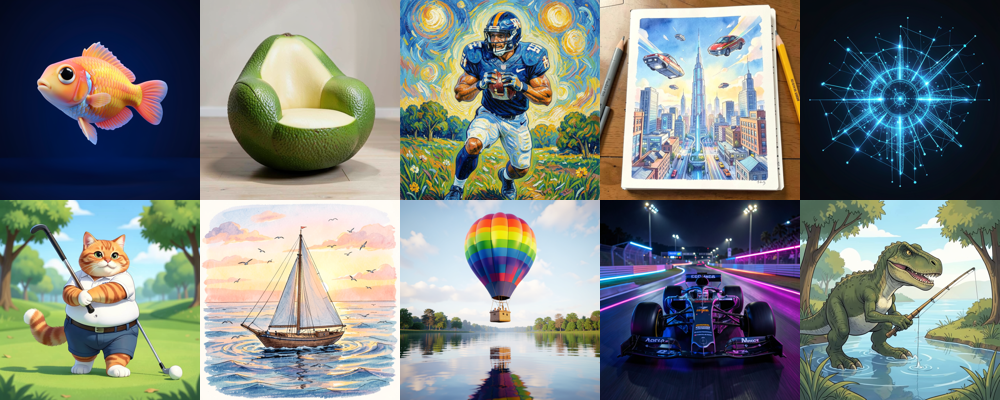

In [7]:
from IPython.display import display

def contact_sheet(runs, thumb=200):
    sheet = Image.new('RGB', (thumb * 5, thumb * 2), 'white')
    for i, g in enumerate(runs[:10]):
        im = Image.open(g['image_file']).convert('RGB')
        im.thumbnail((thumb, thumb))
        sheet.paste(im, ((i % 5) * thumb, (i // 5) * thumb))
    return sheet

print(f'Saved {len(runs)} images to {out_dir(model_name)}/  (row 1: prompts 01-05, row 2: prompts 06-10)')
display(contact_sheet(runs))

## 7. What the images show, and the cost of this run

**Caption check.** A vision model (`Qwen2-VL-2B-Instruct`, from the ITT notebook) describes every generated image in one
sentence, so you can compare what was asked for (`prompt`) with what was drawn (`caption`). It runs after generation,
outside the timed and measured windows, and is unloaded afterwards.

**Per-prompt CSV columns** (`Model_Level_Metrics/<model>_prompt_metrics.csv`):

| Column | Meaning |
|---|---|
| `prompt_id`, `model`, `family`, `size` | which prompt and model |
| `resolution (px)`, `steps`, `guidance`, `seed` | generation settings |
| `input_words`, `input_characters` | length of the prompt |
| `time_to_first_step (ms)` | time until the first denoising step finished (text encoding + one step); Stable Diffusion only, mflux does not expose steps |
| `time_per_step (ms)` | inference time ÷ steps (includes text encoding and decoding) |
| `inference_rate (images/min)`, `inference_time (s)` | images per minute at this speed, and total time for the image |
| `image_file`, `prompt`, `caption` | the PNG, the prompt, and what the vision model sees in the image |

In [8]:
import gc
from mlx_vlm import load as load_vlm, generate as vlm_generate
from mlx_vlm.prompt_utils import apply_chat_template

def caption_images(runs):
    """Describe each generated image in one sentence with a small vision model, then unload it."""
    vlm, proc = load_vlm(CAPTION_MODEL)
    question = apply_chat_template(proc, vlm.config, 'Describe this image in one sentence.', num_images=1)
    for g in runs:
        out = vlm_generate(vlm, proc, question, image=[g['image_file']], max_tokens=80, temperature=0.0, verbose=False)
        g['caption'] = (out.text if hasattr(out, 'text') else str(out)).strip()
    del vlm, proc
    gc.collect()
    mx.clear_cache()

def save_prompt_metrics(name, runs, folder):
    c = MODELS[name]
    rows = [{
        'prompt_id': g['id'], 'model': name, 'family': family_of(name), 'size': size_of(name),
        'resolution (px)': f'{WIDTH}x{HEIGHT}', 'steps': c['steps'],
        'guidance': c['guidance'] if c['guidance'] is not None else '', 'seed': SEED,
        'input_words': g['words'], 'input_characters': g['characters'],
        'time_to_first_step (ms)': round(1000 * g['first_step_s'], 1) if g['first_step_s'] else '',
        'time_per_step (ms)': round(1000 * g['time_s'] / c['steps'], 1),
        'inference_rate (images/min)': round(60 / g['time_s'], 2),
        'inference_time (s)': round(g['time_s'], 3),
        'image_file': g['image_file'], 'prompt': g['prompt'], 'caption': g['caption'],
    } for g in runs]
    path = Path(folder) / f'{name}_prompt_metrics.csv'
    pd.DataFrame(rows).to_csv(path, index=False)
    return path

def simple_metrics(name, runs, load_s):
    s, c = SPECS.loc[name], MODELS[name]
    n = len(runs)
    time_s = sum(g['time_s'] for g in runs)
    measured = runs[0]['power']['energy_j'] is not None
    energy = sum(g['power']['energy_j'] for g in runs) if measured else None
    return {
        'model': name, 'family': family_of(name), 'size': size_of(name), 'repo': c['repo'], 'library': c['library'],
        'parameters_billion': s.params_b, 'precision': c['precision'], 'prompt_set': PROMPT_SET, 'images_generated': n,
        'settings': {'resolution_px': f'{WIDTH}x{HEIGHT}', 'steps': c['steps'], 'guidance': c['guidance'], 'seed': SEED},
        'speed': {
            'model_load_seconds': round(load_s, 1),
            'total_inference_seconds': round(time_s, 1),
            'avg_seconds_per_image': round(time_s / n, 2),
            'avg_ms_per_step': round(1000 * time_s / n / c['steps'], 1),
            'images_per_minute': round(60 * n / time_s, 2),
            'avg_time_to_first_step_ms': round(1000 * sum(g['first_step_s'] for g in runs) / n) if runs[0]['first_step_s'] else None,
            'avg_decode_seconds': round(sum(g['decode_s'] for g in runs) / n, 2) if runs[0]['decode_s'] else None,
        },
        'memory': {'download_gb': float(s.download_gb), 'peak_memory_gb': round(max(g['peak_gb'] for g in runs), 2)},
        **(HARDWARE.get(name) or {'hardware': 'not measured (macmon not available)'}),
        'energy': {
            'total_joules': round(energy, 1) if measured else None,
            'avg_joules_per_image': round(energy / n, 1) if measured else None,
            'watt_hours_per_100_images': round(energy / n * 100 / 3600, 2) if measured else None,
        },
        'cost_usd': {
            'api_fee': 0.0,
            'electricity_whole_run': round(energy / 3.6e6 * ELECTRICITY_USD_PER_KWH, 6) if measured else None,
            'electricity_per_1000_images': round(energy / n * 1000 / 3.6e6 * ELECTRICITY_USD_PER_KWH, 4) if measured else None,
            'electricity_price_per_kwh': ELECTRICITY_USD_PER_KWH,
        },
        'per_image': [{'id': g['id'], 'seconds': round(g['time_s'], 2), 'energy_joules': g['power']['energy_j'],
                       'image_file': g['image_file'], 'caption': g['caption']} for g in runs],
    }

def finish_model(name, runs, model_dir, load_s):
    caption_images(runs)
    csv_path = save_prompt_metrics(name, runs, model_dir)
    sm = simple_metrics(name, runs, load_s)
    (out_dir(name) / f'{name}_simple_metrics.json').write_text(json.dumps(sm, indent=2))
    print(f'Per-prompt metrics: {csv_path}')
    return sm

sm = finish_model(model_name, runs, model_dir, load_seconds)
rows = [
    ('Images', f"{sm['images_generated']} at {sm['settings']['resolution_px']}, {sm['settings']['steps']} steps"),
    ('Total inference time', f"{sm['speed']['total_inference_seconds']} s ({sm['speed']['avg_seconds_per_image']} s per image)"),
    ('Images per minute', sm['speed']['images_per_minute']),
    ('Time per step (avg)', f"{sm['speed']['avg_ms_per_step']} ms"),
    ('Peak memory', f"{sm['memory']['peak_memory_gb']} GB"),
    ('API cost', '$0.00 (runs locally)'),
]
if sm['energy']['total_joules'] is not None:
    rows += [
        ('GPU busy / power (avg)', f"{sm['gpu']['avg_utilization_pct']}% / {sm['gpu']['avg_power_watts']} W"),
        ('CPU busy / power (avg)', f"{sm['cpu']['avg_utilization_pct']}% / {sm['cpu']['avg_power_watts']} W"),
        ('NPU (Neural Engine) power (avg)', f"{sm['npu']['avg_power_watts']} W"),
        ('Energy per image', f"{sm['energy']['avg_joules_per_image']} J"),
        (f'Electricity per 1,000 images (at ${ELECTRICITY_USD_PER_KWH}/kWh)', f"${sm['cost_usd']['electricity_per_1000_images']}"),
    ]
display(pd.DataFrame(rows, columns=['Metric', model_name]).style.hide(axis='index'))
pd.read_csv(Path(model_dir) / f'{model_name}_prompt_metrics.csv', dtype={'prompt_id': str})[
    ['prompt_id', 'inference_time (s)', 'time_per_step (ms)', 'prompt', 'caption']].style.hide(axis='index')

Fetching 11 files:   0%|          | 0/11 [00:00<?, ?it/s]

Fetching 11 files: 100%|██████████| 11/11 [00:00<00:00, 4426.49it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Per-prompt metrics: metrics_analysis/tti/FLUX.2-klein/4B/tti_prompts_10/Model_Level_Metrics/FLUX.2-klein-4B_prompt_metrics.csv


Metric,FLUX.2-klein-4B
Images,"10 at 1024x1024, 4 steps"
Total inference time,42.7 s (4.27 s per image)
Images per minute,14.070000
Time per step (avg),1066.4 ms
Peak memory,18.66 GB
API cost,$0.00 (runs locally)
GPU busy / power (avg),94.6% / 59.0 W
CPU busy / power (avg),4.4% / 3.5 W
NPU (Neural Engine) power (avg),0.0 W
Energy per image,295.7 J


prompt_id,inference_time (s),time_per_step (ms),prompt,caption
01,3.937000,984.100000,"3D render of a cute tropical fish in an aquarium on a dark blue background, digital art","The image features a vibrant, colorful fish with a large, expressive eye, swimming against a dark blue background."
02,4.006000,1001.600000,An armchair in the shape of an avocado,"The image shows a unique chair designed to resemble an avocado, with a green exterior and a yellow interior."
03,4.019000,1004.700000,A van Gogh style painting of an American football player,"The image is a painting of a football player in a field, wearing a blue uniform with a helmet, holding a football. The background features swirling, starry skies with yellow suns."
04,4.068000,1017.000000,A pencil and watercolor drawing of a bright city in the future with flying cars,"The image is a colorful illustration of a futuristic cityscape featuring tall buildings, flying cars, and a bright sky."
05,4.138000,1034.500000,An abstract visual of artificial intelligence,"The image features a glowing, abstract design resembling a compass rose, with lines extending from the center to form a star-like pattern. The overall effect is bright and colorful, with a blue and white color scheme."
06,4.308000,1076.900000,A Fat Cat playing Golf,"The image features a cartoon cat dressed in a white shirt and blue shorts, holding a golf club and a golf ball on a grassy field with trees in the background."
07,4.453000,1113.200000,A hand-drawn sailboat circled by birds on the sea at sunrise,"The image depicts a sailboat sailing on the ocean with a beautiful sunset in the background, featuring a red flag and seagulls flying above."
08,4.550000,1137.400000,A 3D render of a rainbow colored hot air balloon flying above a reflective lake,"A colorful hot air balloon with a rainbow-striped pattern floats over a serene lake, creating a picturesque scene."
09,4.584000,1145.900000,A Formula 1 car driving on a neon road,"A Formula One race car is driving on a track at night, with neon lights creating a vibrant, colorful atmosphere."
10,4.595000,1148.800000,illustration of a dinosaur enjoying a peaceful fishing experience,A dinosaur is fishing in a pond surrounded by trees.


## 8. Compare every size in the family

Runs the prompts through every other size of `FAMILY` (each TTI family here currently has one MLX-usable size, so this
section mainly matters if more sizes are added to the registry). Set `TTI_COMPARE=0` to skip.

In [9]:
results = {SIZE: (sm, runs)}
if RUN_FAMILY_COMPARISON:
    for size, name in MODEL_NAME[PLATFORM][TASK][FAMILY].items():
        if size == SIZE:
            continue
        del model
        gc.collect()
        mx.clear_cache()
        print(f'{size}: {name}')
        model, load_s = load_tti_model(name)
        r, mdir = run_prompt_set(model, name)
        results[size] = (finish_model(name, r, mdir, load_s), r)
order = [s for s in ('SMALL', 'MEDIUM', 'LARGE') if s in results]
pd.DataFrame({s: {'Model': r_['model'], 'Seconds / image': r_['speed']['avg_seconds_per_image'],
                  'Images / min': r_['speed']['images_per_minute'], 'Peak memory (GB)': r_['memory']['peak_memory_gb'],
                  'Energy / image (J)': r_['energy']['avg_joules_per_image']}
              for s in order for r_ in [results[s][0]]})

,SMALL
Model,FLUX.2-klein-4B
Seconds / image,4.27
Images / min,14.07
Peak memory (GB),18.66
Energy / image (J),295.7


## 9. All models on this prompt set

`outputs/tti/all_models_<prompt set>.json` / `.csv` from the simple metrics, and
`metrics_analysis/tti/all_models_prompt_metrics_<prompt set>.csv` from the per-prompt CSVs.

In [10]:
FAMILY_ORDER = list(MODEL_NAME[PLATFORM][TASK])
SIZE_ORDER = ['SMALL', 'MEDIUM', 'LARGE']
files = Path('outputs/tti').glob(f'*/*/{PROMPT_SET}/*_simple_metrics.json')
models = sorted((json.loads(f.read_text()) for f in files),
                key=lambda m: (FAMILY_ORDER.index(m['family']), SIZE_ORDER.index(m['size'])))
overview = [{k: v for k, v in m.items() if k != 'per_image'} for m in models]
all_json = Path('outputs/tti') / f'all_models_{PROMPT_SET}.json'
all_json.write_text(json.dumps({'prompt_set': PROMPT_SET, 'models': overview}, indent=2))
flat = pd.json_normalize(overview)
flat.to_csv(all_json.with_suffix('.csv'), index=False)
print(f'{len(models)} models -> {all_json} and {all_json.with_suffix(".csv")}')
pd.DataFrame({
    'Family': flat['family'], 'Size': flat['size'], 'Model': flat['model'], 'Params (B)': flat['parameters_billion'],
    'Steps': flat['settings.steps'], 'Seconds / image': flat['speed.avg_seconds_per_image'],
    'Images / min': flat['speed.images_per_minute'], 'Peak memory (GB)': flat['memory.peak_memory_gb'],
    'GPU busy (%)': flat.get('gpu.avg_utilization_pct'), 'GPU power (W)': flat.get('gpu.avg_power_watts'),
    'CPU busy (%)': flat.get('cpu.avg_utilization_pct'), 'NPU power (W)': flat.get('npu.avg_power_watts'),
    'Energy / image (J)': flat['energy.avg_joules_per_image'],
}).style.hide(axis='index')

2 models -> outputs/tti/all_models_tti_prompts_10.json and outputs/tti/all_models_tti_prompts_10.csv


Family,Size,Model,Params (B),Steps,Seconds / image,Images / min,Peak memory (GB),GPU busy (%),GPU power (W),CPU busy (%),NPU power (W),Energy / image (J)
Stable-Diffusion-XL,MEDIUM,stable-diffusion-xl-base-1.0,3.470000,30,11.720000,5.120000,21.370000,96.700000,53.700000,8.400000,0.000000,743.400000
FLUX.2-klein,SMALL,FLUX.2-klein-4B,4.000000,4,4.270000,14.070000,18.660000,94.600000,59.000000,4.400000,0.000000,295.700000


In [11]:
prompt_csvs = sorted(Path('metrics_analysis/tti').glob(f'*/*/{PROMPT_SET}/Model_Level_Metrics/*_prompt_metrics.csv'))
all_prompts = pd.concat([pd.read_csv(p, dtype={'prompt_id': str}) for p in prompt_csvs], ignore_index=True)
all_prompts['family'] = pd.Categorical(all_prompts['family'], FAMILY_ORDER, ordered=True)
all_prompts['size'] = pd.Categorical(all_prompts['size'], SIZE_ORDER, ordered=True)
all_prompts = all_prompts.sort_values(['family', 'size', 'prompt_id'])
combined_csv = Path('metrics_analysis/tti') / f'all_models_prompt_metrics_{PROMPT_SET}.csv'
all_prompts.to_csv(combined_csv, index=False)
print(f'{len(prompt_csvs)} models, {len(all_prompts)} prompt rows -> {combined_csv}')
all_prompts.groupby(['family', 'size', 'model'], observed=True).agg(
    images=('prompt_id', 'count'), total_time_s=('inference_time (s)', 'sum'),
    avg_time_per_step_ms=('time_per_step (ms)', 'mean'), avg_images_per_min=('inference_rate (images/min)', 'mean')).round(2)

2 models, 20 prompt rows -> metrics_analysis/tti/all_models_prompt_metrics_tti_prompts_10.csv


,,,images,total_time_s,avg_time_per_step_ms,avg_images_per_min
family,size,model,,,,
Stable-Diffusion-XL,MEDIUM,stable-diffusion-xl-base-1.0,10,117.24,390.80,5.12
FLUX.2-klein,SMALL,FLUX.2-klein-4B,10,42.66,1066.41,14.11
